# Year 5 Pipeline - restarting the exosearch 
### Notes:
- Year: Year 5, chosen for it's overlapping sectors in the CVZ as seen by the MIT graph 
- Sectors: S61-S69
- If using Great Lakes Computing Cluster or Treefort, use Cisco Secure Client to get a VPN to connect to the University of Michigan network.

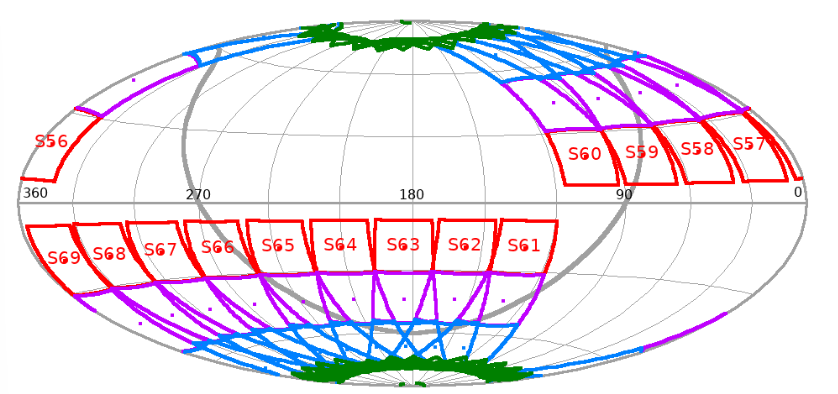




### Steps:

1. Upload files from Github or upload them directly to Treefort (all .sh, .py files in Github). Make your own directory orgnized with files (full structure can be seen in github). Install python packages listed below. For work in TreeFort install using: "pip install lightkurve --break-system-package" to install if facing issues. 

1. Download the.sh file from github and run download_lists.sh to get a list of candidate targets in the chosen sectors.
    - to upload the file from your home laptop/directory TO vs code run the following command in your HOME (laptop) terminal:
        scp C:\Users\theirusername\Downloads\download_lists.sh theirusername@treefort.astro.lsa.umich.edu:~/


2. Get the persistent TIC's across all 9 sectors using the downloaded lists from above (the targets which have continuous observations across all sectors). NOTE: Change sector limits using nano if using any other year of data. 

3. Download the CBV (Co-trending basis vector) files for sectors 61-69 in BASH (terminal) using the command below, you should get files like "tesscurl_sector_61_cbv.sh". These files are the systematic noise patterns from TESS.
    - Downloads shell scripts provided by MAST that contail all the curl download commands for a given sector. Each script contains 16 curl commands, one for each camera/CCD combo.
    - This website only works for more recent years of data, to do this by hand you can download the files online at "https://archive.stsci.edu/tess/bulk_downloads/bulk_downloads_ffi-tp-lc-dv.html" .

4. Download the CBV FITS files - Same as CBV files above but in FITS format. You should get files like "tess2023043185947-s0062-1-4-0245-s_cbv.fits" which represent tess{timestamp}-s{sector:04d}-{cam}-{ccd}-{version}-s_cbv.fits.
    - Runs the downloaded shell scripts from above. Each script uses curl to download the CBV data files in FITS format from MAST. These FITs files contain the actual basis vector data. 

5. Get the cadence bounds for sectors 61-69 from the CBV FITS Files (or whatever relevant sectors you are using).

6. Create a new info_yX.py file (where X is your TESS year for example) in ~/TESS/data/light_curves/info/ with cadence bounds from step 5 and your sector range (See format in README). Update ~/tess_transit/data/loader.py to import from your new info file instead of info.py. NOTE: look at the README for clear instructions and tips on this step for what to change. 
    - in short, we use this file to have a place to put the year, sectors, and cadence bounds of the sectors (cadence bounds are the timesteps). Location for this file is not important as long as you know where to find it. 
    - NOTE: make sure you update loader.py

6. Run vector_matrix.py in BASH (terminal) using info_y5.py. You should get files like " evec_matrix_69_4_4.p". NOTE: make sure you nano into the .py file and change the filepaths and sector limits to your own.
    - loops through every sector (61-69), camera (1-4), and CCD (1-4) combination, opens the CBV FITS file, exctracts the 30 basis vectors, maps then onto a full cadence-length array usng cadence bounds, saves results in a pickle file. 
    

7. Run the light curve download script (download_lc_y5.py).
    - This step will be time consuming, it would be smart to run this in the background in a terminal. This script downloads the light curve from MAST (via lightkurve, make sure you have this downloaded), specifically the SPOC 2-minute cadence SAP and PDCSAP flux.
    - Then, the data is extracted (SAP flux, PDCSAP flux, cadence numbers, camera/CCD, centroid positions, position correcctions, and quality flags).
    - Loads the evec matrix for the corresponding sector/camera/CCD, detrends the light curve by projecting the SAP flux onto the evec basis vectors and subtracting the systematic component. 
    - Saved everything as a pickle file {TIC_ID}.p to ~/TESS/data/lightcurves_y5/

8. Go into the "multi_target_run_y5.py" script and modify it for the sectors you are using. Input your lightcurve directory (LC_DIR), and where you want the results to go (RESULTS_DIR). OPTIONAL modify: durations, min_period, max_period, and min_transits to be what you want. 
    - This script runs the FFT_based mached filter transit search (developed by Dr. Taaki) on all preprocessed light curves. For each target it loads the light curve pickle file, searches for periodic transit signals across all available sectors using transit durations (between 1 hour (30 cadences) and 4 hours (120 cadences)).
    - This script skips targets that already have results so it IS safe to restart if interrupted.
    - The estimated runtime is 10 hours. 
    - This script would normally take up LOTS of space (~2.5GB per target), however, I added the SNR filter directly into this .py. In the old run (older files), this step was performed after the search was finished using filter_snr.py.
        - The SNR threshold is SNR ≥ 6, targets will are detections below SNR 6 are zeroed out before saving. This threshold can be changed. 
    - NOTE: the FFT Search will return a series of "detections" where the combination of duration, period, and epoch of a planet transit has a high SNR fit to the motion seen in the lightcurve data. We perform vetting on the best fitting results to make sure there is a real transit and not systematic errors, an eclipsing binary, etc. The other results can be accessed like best_results[n] for n = 0, 1, 2, ...

9. Run the vetting on all of the targets you have passed through the FFT search. Below there are cells to investigate the vetting before you go through and run it on all of the targets. 
    - Note: you can run it in the notebook here which will take a long time depending on how many targets you have or you can run "vetting_y5.py" to run the full vetting in the BASH to have it run in the background. Make sure to adjust any thresholds, and filepath names as needed.
    - STEPS:
        - 1. run "vetting_y5.py" to run the vetting tests on the targets after the FFT search. This will output a score for each vetting test, an Rp/Rstar depth calculation, period, and a combined score as well as verdict for each target whether they passed vetting or not, with some targets labeled as a "maybe" (I have found a few planets in this maybe category in the last run, which is why I include it here)
        - 2. Run the "images_y5.py" file to generate a 3 graph figure with the full light curve, phase folded light curve, and a zoomed in phase fold with transit points highlighted in green.

### Note:
- Only year 5 was chosen for the rerun due to the consecutive nature of the search - this can be reperformed for other sectors, years, etc. 
- Use Python global environment (Python 3.12.3)
- TIC = TESS Input Catalog - catalog of stars that TESS uses to select which stars to observe
- TID (what I use, not official) - TIC ID number - every star in the catalog gets a unique TID number (ex: TIC 219879302)

### Numbers:
- Persistent tics 1299
- CBV FITS Files = 368 (9 Sectors x 16 Camera/CCD combinations - some may have multiples)


### Required software:
- lightkurve package
- astropy
- numpy
- scipy
- matplotlib
- Python 3.12.3

In [1]:
# util information

year = 5
sectors = [61, 69]
cadence_bounds = {
    61: (1249444, 1267755),
    62: (1267906, 1286422),
    63: (1286574, 1305680),
    64: (1305831, 1325215),
    65: (1325721, 1345805),
    66: (1346554, 1367260),
    67: (1367411, 1387397),
    68: (1387549, 1407372),
    69: (1407524, 1426092)
}

In [2]:
# imports 
import pandas as pd
from astropy.io import fits
import glob

In [3]:
# Step 2 - get persistent TICS across all 9 sectors

# get a list of ALL tic ids
all_tids_set = []
for i in range(61, 70):
    table_file = f"/home/juliajos/TESS/data/light_curves/info/all_targets_S0{i}_v1.txt"  # downloaded using download_lists.sh
    data = pd.read_csv(table_file, comment='#', delimiter='\t')
    tids = set(data.iloc[:,0])
    all_tids_set.append(tids)

# get the tids that are persistent across all 9 sectors
common_tics = set.intersection(*all_tids_set)
print(f"Persistent TICs in sectors 1-9: {len(common_tics)}")

# save persistent tics to a file
with open("/home/juliajos/TESS/data/light_curves/info/persistant_tids_y5.txt", "w") as f:
    for tid in sorted(common_tics):
        f.write(f"{tid}\n")


Persistent TICs in sectors 1-9: 1299


### STEP 3: RUN IN TERMINAL

In [16]:
# Step 3 - download the CBV shell scripts for each sector

'''
cd ~/TESS/data/light_curves/info/cbvs/
for s in $(seq -f "%02g" 61 69); do
    wget "https://archive.stsci.edu/missions/tess/download_scripts/sector/tesscurl_sector_${s}_cbv.sh"
done
'''

'\ncd ~/TESS/data/light_curves/info/cbvs/\nfor s in $(seq -f "%02g" 61 69); do\n    wget "https://archive.stsci.edu/missions/tess/download_scripts/sector/tesscurl_sector_${s}_cbv.sh"\ndone\n'

## STEP 4: RUN IN TERMINAL

In [ ]:
# step 4 - run the CBV shell scripts to download FITS files:

'''
for s in $(seq -f "%02g" 61 69); do
    echo "Downloading CBVs for sector $s..."
    bash tesscurl_sector_${s}_cbv.sh
done
'''

'\nfor s in $(seq -f "%02g" 61 69); do\n    echo "Downloading CBVs for sector $s..."\n    bash tesscurl_sector_${s}_cbv.sh\ndone\n'

In [4]:
# Step 5 - Get the cadence bounds from the CBV FITS files

for sector in range(61, 70):
    pattern = f'/home/juliajos/TESS/data/light_curves/info/cbvs/*s{sector:04d}*1-1*.fits'
    files = glob.glob(pattern)
    if files:
        with fits.open(files[0]) as hdu:
            cadences = hdu[1].data['CADENCENO']
            print(f"sector {sector}: ({cadences.min()}, {cadences.max()})")
    else:
        print(f"sector {sector}: no file found")

sector 61: (1249444, 1267755)
sector 62: (1267906, 1286422)
sector 63: (1286574, 1305680)
sector 64: (1305831, 1325215)
sector 65: (1325721, 1345805)
sector 66: (1346554, 1367260)
sector 67: (1367411, 1387397)
sector 68: (1387549, 1407372)
sector 69: (1407524, 1426092)


## STEP 6: RUN IN TERMINAL
- Note: Change filepaths in vector_matrix.py before running
- Note: Check the filepaths in loader.py file

In [ ]:
# Step 6 - Run vector_matrix.py in BASH
# make sure to go into the vector_matrix.py file and change your filepaths, sectors, and info.py file before running the following command
'''
python3 ~/TESS/code/preprocess/vector_matrix.py
''';

## STEP 7: RUN IN TERMINAL

In [5]:
# step 7 - Download the light curves for the persistent TICS in BASH
'''
nohup python3 ~/TESS/code/preprocess/download_lc_y5.py > download_lc_y5.log 2>&1 &
tail -f download_lc_y5.log
''';

## Step 8: RUN IN TERMINAL
- NOTE: this is where you run the planet search. If you nano into the multi_target_run_y5.py file this is where you can change the duration, period, and epoch grids.

In [ ]:
# step 8 - modify the "multi_target_run_y5.py" script to adjust to the sectors you're using, run in terminal
# modify LC_DIR, RESULTS_DIR, and optionally: durations, min_period_days, max_period_days, min_transits


# IMPORTANT NOTE: if you open up the script you can change the duration grid, period grid and minimum number of transits, this will likely be important for a disentegrating planet search.

'''
nohup python3 ~/tess_transit/multi_target_run_y5.py > multi_target_run_y5.log 2>&1 &
tail -f multi_target_run_y5.log
'''

# check progress
'''
grep "Done" multi_target_run_y5.log | wc -l
''';

# Complete Vetting: Post Search - vetting candidates for false positives, EB's, etc. 
- NOTE: change your filepaths to match the input and output directories
- you can go to EXOPFOP or NASA Exoplanet Archive to see if there is a confimed planet at the TIC you are searching

### Important Functions, imports, and information to have before running the vetting

In [5]:
# step 9 - vetting imports and setup 
# updating paths for year 5

#imports
import gc
import numpy as np
import matplotlib.pyplot as plt
import os
import pickle
import sys
sys.path.insert(0, '/home/juliajos')
sys.path.insert(0, '/home/juliajos/TESS/data/light_curves/info')

from scipy.stats import pearsonr, binom, ttest_ind, norm
from tess_transit.search import run_search, SearchConfig
from tess_transit.data.loader import load_pickle, get_lightcurve, available_sectors
from info_y5 import cadence_bounds

plot = False #change to True if you want to plot the centroid motion and even odd sector by sector, outputs ~8 plots per target

CADENCE_DURATION_DAYS = 2 / (24*60) # 2 minute cadence duration in days *CHECK TO SEE CADENCE DURATION IN DIFFERENT YEARS/WHAT YOU DOWNLOAD*

# year 5 paths - update your paths here
RESULTS_DIR  = "/home/juliajos/tess_transit/data/output_y5"             # search results
LAB_DIR      = os.path.expanduser("~/TESS/data/lightcurves_y5")         # lightcurve files
SECTORS      = [61, 62, 63, 64, 65, 66, 67, 68, 69]                     # sector range you are working over
first_sector = SECTORS[0]

# output directories
VETTING_DIR = "/home/juliajos/tess_transit/data/vetting__results_y5"    # where you want the vetting results to go
IMAGES_DIR  = "/home/juliajos/tess_transit/data/vetting__images_y5"     # where you want the resulting phase folded images and vetting images to go
os.makedirs(VETTING_DIR, exist_ok=True)                                 # if you do not already have these files this will make them for you
os.makedirs(IMAGES_DIR, exist_ok=True)

#util functions
def cadence_to_days(n_cadences):
    '''
    Convert number of cadences to days, given the cadence duration in days.
    '''
    return n_cadences * CADENCE_DURATION_DAYS

def cadences_to_btjd(cadence_numbers):
    '''
    Convert number of cadences to BTJD, given the cadence duration in days. (Barycentric TESS Julian Date)
    '''
    return cadence_numbers * (120 / 86400)

def epoch_to_btjd(epoch_cadences, duration_cadences):
    '''
    Convert epoch and duration in cadences to BTJD.
    The epoch is the start of the transit in cadences, and the duration is the length of the transit in cadences.
    The function returns the BTJD of the midpoint of the transit.'''
    return (epoch_cadences + duration_cadences / 2) * (120 / 86400)

def in_transit_mask(time_bjd, period_days, t0_bjd, duration_days):
    """Boolean mask: True where time falls within a transit window."""
    if period_days <= 0 or duration_days <= 0:
        return np.zeros_like(time_bjd, dtype=bool)
    phase = ((time_bjd - t0_bjd + 0.5 * period_days) % period_days) - 0.5 * period_days
    return np.abs(phase) <= 0.5 * duration_days

#vetting test functions
def even_odd_phase_our_data(flux, time_btjd, period_days, t0_btjd, duration_days, plot_size=0.15, same_axes=False, plot=False):
    '''
    Perform an even-odd transit depth test on the provided light curve data. 
    '''
    
    flux     = np.array(flux,     dtype=float)
    time_btjd = np.array(time_btjd, dtype=float)

    phase_full  = ((time_btjd - t0_btjd) % period_days) / period_days
    phase_folded = phase_full - np.round(phase_full)

    transit_num = np.floor((time_btjd - t0_btjd) / period_days).astype(int)

    half_window     = duration_days / (2 * period_days)
    in_transit      = np.abs(phase_folded) < half_window
    in_transit_odd  = in_transit & (transit_num % 2 == 1)
    in_transit_even = in_transit & (transit_num % 2 == 0)

    odd_depths  = 1 - flux[in_transit_odd]
    even_depths = 1 - flux[in_transit_even]
    odd_clean   = odd_depths[~np.isnan(odd_depths)]
    even_clean  = even_depths[~np.isnan(even_depths)]

    p_val = np.nan
    mean_odd = mean_even = np.nan
    if len(odd_clean) > 1 and len(even_clean) > 1:
        try:
            _, p_val  = ttest_ind(odd_clean, even_clean) #we use a t test to see if the difference is statistically significiant
            mean_odd  = float(np.nanmean(odd_depths))
            mean_even = float(np.nanmean(even_depths))
        except Exception as e:
            print(f"    t-test error: {e}")

    if plot:
        fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
        ax[0].plot(phase_odd,  flux, lw=0, color='navy',   marker='.', alpha=0.4)
        ax[1].plot(phase_even, flux, lw=0, color='maroon', marker='.', alpha=0.4)
        for a, label in zip(ax, ['ODD', 'EVEN']):
            a.set_xlabel('Phase')
            a.annotate(label, (0.3, np.nanmin(flux)), fontsize=14)
            a.set_xlim(-plot_size, plot_size)
        ax[0].set_ylabel('Normalized flux')
        plt.subplots_adjust(wspace=0.02)
        if not np.isnan(p_val):
            stat_text = (f"Odd depth:  {mean_odd:.4g}\n"
                         f"Even depth: {mean_even:.4g}\n"
                         f"p = {p_val:.2g}")
            ax[0].text(0.05, 0.95, stat_text, transform=ax[0].transAxes,
                       fontsize=10, va='top', bbox=dict(facecolor='white', alpha=0.7))
        plt.suptitle("Even-Odd Test (INJECTED transit)", fontsize=13)
        plt.tight_layout()
        plt.show()

    return p_val


def calculate_enhanced_centroid_motion_pvalue(lc_flux, time_btjd, mom1, mom2, pos1, pos2, period_days, t0_btjd, duration_days,
    baseline_factor=3.0, sector=None, plot=True):
    ''' 
        Calculate the enhanced centroid motion p-value for a given light curve and centroid data.
        This function computes the correlation between flux variations and centroid shifts during predicted transit times.
        It also checks for outliers in the centroid data during transit windows compared to baseline windows.
        The final p-value is combined using Stouffer's method to provide an overall significance measure
        '''
    time_btjd = np.asarray(time_btjd, dtype=float) #x points on a lightcurve
    lc_flux  = np.asarray(lc_flux,  dtype=float) #y points on a lightcurve
    mom1     = np.asarray(mom1,     dtype=float) #momentum based center of light
    mom2     = np.asarray(mom2,     dtype=float)
    pos1     = np.asarray(pos1,     dtype=float) #centroid fitted position center of light
    pos2     = np.asarray(pos2,     dtype=float)

    centroid_x = mom1 - pos1 #center of light location
    centroid_y = mom2 - pos2

    #plotting
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4))
        axes[0].scatter(time_btjd, lc_flux,    s=3); axes[0].set_title('Lightcurve')
        axes[1].scatter(time_btjd, centroid_x, s=3); axes[1].set_title('Centroid X')
        axes[2].scatter(time_btjd, centroid_y, s=3); axes[2].set_title('Centroid Y')
        for a in axes: a.set_xlabel('BTJD')
        plt.tight_layout()
        plt.show()

    t_start, t_end = time_btjd[0], time_btjd[-1] #observation window in time
    n_min = int(np.floor((t_start - t0_btjd) / period_days)) #indices of transits relative to reference transit (n = 1, text transit, etc.)
    n_max = int(np.ceil( (t_end   - t0_btjd) / period_days))
    transit_times = [t0_btjd + n * period_days for n in range(n_min, n_max + 1) #expected transit midpoints using the periods
                     if t_start <= t0_btjd + n * period_days <= t_end] #len(transit_times) = number of transits in the data

    if len(transit_times) == 0:
        print(f"  Sector {sector}: no predicted transits in range.")
        return np.nan

    spike_dur       = min(duration_days, 0.5) #transit window
    baseline_window = duration_days * baseline_factor #baseline where no transit
    all_p_values    = []

    for tt in transit_times:
        transit_mask  = (time_btjd > tt - spike_dur / 2) & (time_btjd < tt + spike_dur / 2) #points inside transit
        baseline_mask = ((time_btjd > tt - baseline_window) & (time_btjd < tt + baseline_window) & ~transit_mask) #points where baseline

        if np.sum(transit_mask) < 2 or np.sum(baseline_mask) < 5: #making sure we have enough data points
            continue

        cx_tr = centroid_x[transit_mask];  cy_tr = centroid_y[transit_mask] #transit centroid values during single transit window
        cx_bl = centroid_x[baseline_mask]; cy_bl = centroid_y[baseline_mask] #baseline centroid values
        flux_tr  = lc_flux[transit_mask] 
        flux_dev = (flux_tr / np.nanmedian(flux_tr)) - 1.0 #normalized flux

        for cx in [cx_tr, cy_tr]:
            valid = ~np.isnan(cx) & ~np.isnan(flux_dev)
            if np.sum(valid) >= 3:
                _, p = pearsonr(flux_dev[valid], cx[valid]) #pearson correlation for centroid shift and flux change
                all_p_values.append(p)

                
        #check this -> look to see if we already do this earlier in testing
        for c_tr, c_bl in [(cx_tr, cx_bl), (cy_tr, cy_bl)]: #comparing transit and baseline points
            bl_clean = c_bl[~np.isnan(c_bl)]
            tr_clean = c_tr[~np.isnan(c_tr)]
            if len(bl_clean) > 5 and len(tr_clean) > 0:
                outliers = np.abs(tr_clean - np.median(bl_clean)) > 5 * np.std(bl_clean) #transits points that deviate more than 3 sigma
                if np.sum(outliers) > 0:
                    '''
                    if outliers, binomial distribution, basically looking for shifts in the centroid points, if no centroid shift, no outliers
                    assumes gaussian noise
                    '''
                    p_sp = 1 - binom.cdf(np.sum(outliers) - 1, len(tr_clean), 0.003) 
                    all_p_values.append(p_sp)

    if len(all_p_values) == 0:
        return np.nan
    return stouffers_method(all_p_values)

def stouffers_method(p_values):  #z score
    '''
    Combine p-values using Stouffer's method.
    '''
    clean = [p for p in p_values if p is not None and not np.isnan(p)]
    if len(clean) == 0:
        return np.nan
    # clip to avoid infinite z-scores
    clipped = [max(min(p, 1 - 1e-10), 1e-10) for p in clean]
    z_scores = [norm.ppf(p) for p in clipped]
    combined_z = np.sum(z_scores) / np.sqrt(len(z_scores))
    return float(norm.cdf(combined_z))

def combined_score_weighted(centroid_p, eop_p):
    ''' Combine the centroid and EOP p-values using a weighted average. '''
    return (3 * min(centroid_p, 1.0) + 1 * min(eop_p, 1.0)) / 4


### How to create the data to simulate an injected transit - you may be able to modify this for a disentegrating planet transit template

In [11]:
# OPTIONAL: injected transit data you can run through vetting to see if the vetting is going to work 

# injection parameters
TARGET_LC = "/home/juliajos/tess_transit/data/lightcurves/160602429.p"
TARGET_ID = os.path.splitext(os.path.basename(TARGET_LC))[0]
SECTORS     = [73, 74, 75, 76, 77]   # which sectors to use

INJECT_PERIOD   = 4320   # cadences — 6 days
INJECT_DURATION = 60     # cadences — 2 hours

# gathering LC data to inject
raw_data  = load_pickle(TARGET_LC)
lc_list   = [get_lightcurve(raw_data, s) for s in SECTORS]
first_lc  = lc_list[0]

# t0: place first transit 100 cadences into the first sector
INJECT_T0 = first_lc.start_cadence + 100

# depth: 5x the noise std so it's clearly detectable
flux_std    = np.std(first_lc.flux)
INJECT_DEPTH = 5.0 * flux_std

period_days   = cadence_to_days(INJECT_PERIOD)
duration_days = cadence_to_days(INJECT_DURATION)
first_cadence = min(lc.start_cadence for lc in lc_list)
first_sector  = SECTORS[0]
t0_btjd       = epoch_to_btjd(INJECT_T0, INJECT_DURATION)

print("=" * 60)
print(f"TARGET:   TIC {TARGET_ID}")
print(f"Period:   {INJECT_PERIOD} cad  ({period_days:.3f} days)")
print(f"Duration: {INJECT_DURATION} cad  ({duration_days*24:.1f} hours)")
print(f"Depth:    {INJECT_DEPTH:.4f}  ({INJECT_DEPTH/flux_std:.1f} sigma)")
print(f"t0:       {INJECT_T0} cad  (TJD {t0_btjd:.4f})")
print("=" * 60)

del raw_data, lc_list, first_lc
gc.collect()

TARGET:   TIC 160602429
Period:   4320 cad  (6.000 days)
Duration: 60 cad  (2.0 hours)
Depth:    59.2390  (5.0 sigma)
t0:       1482104 cad  (TJD 2058.5194)


0

### Visualization Cell: What does the lightcurve and phase fold look like for the target you are running through the vetting following?

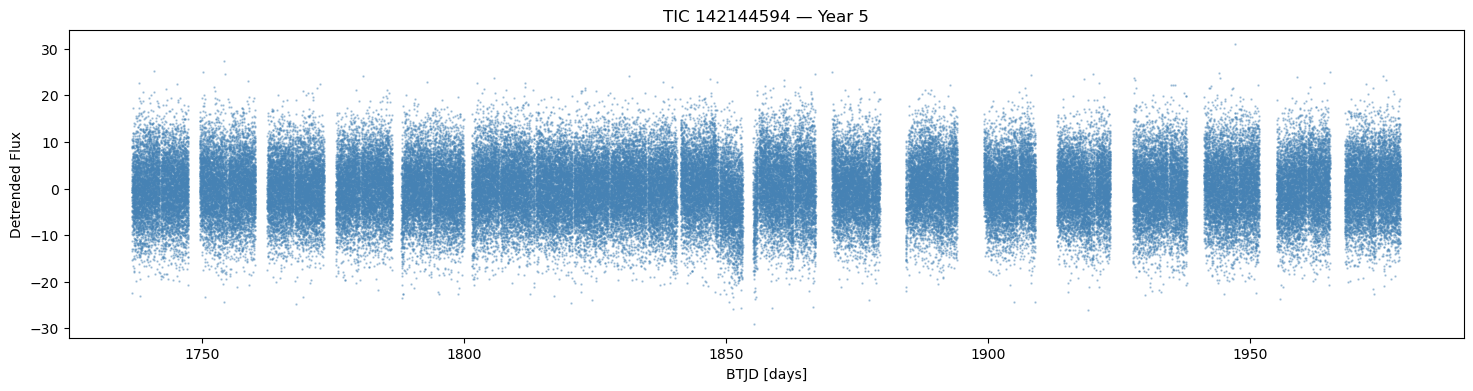

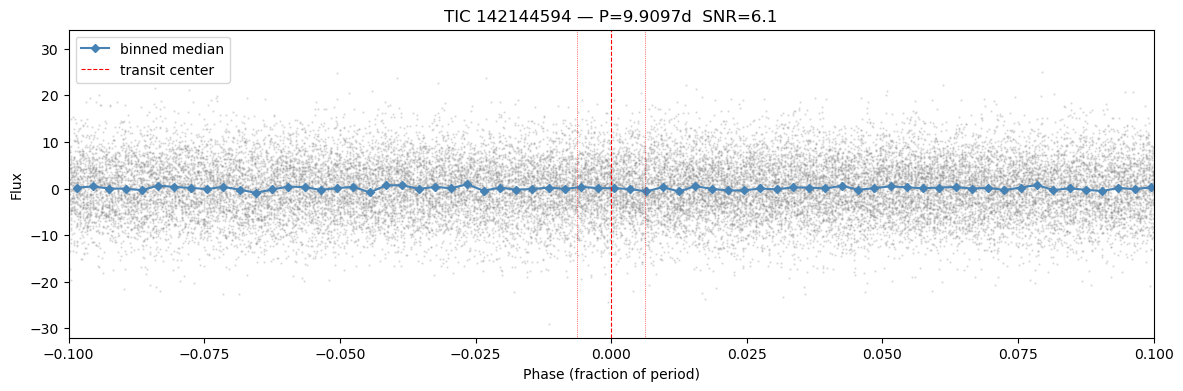

TIC 142144594: P=9.9097d, SNR=6.1


In [6]:
# visualization of a single target used in vetting next cell (just so you can see what it looks like)

target = "142144594"                                    # you can change this here to look at different targets
SECTORS = [61, 62, 63, 64, 65, 66, 67, 68, 69]          # Update with working sector range

lab_path = f"/home/juliajos/TESS/data/lightcurves_y5/{target}.p"    # As always, make sure to update this path to your lightcurve file for the target you want to visualize
with open(lab_path, "rb") as f:
    (lc_data, processed_lc_data, detrend_data, norm_offset, quality_data,
     time_data, cam_data, ccd_data, coeff_ls,
     centroid_xy_data, pos_xy_corr) = pickle.load(f)

cad  = np.concatenate([np.asarray(time_data[s], dtype=float) for s in SECTORS if s in time_data])
flux = np.concatenate([np.asarray(detrend_data[s].unmasked) for s in SECTORS if s in detrend_data])
bjd  = cad * (120 / 86400)

sort_idx = np.argsort(bjd)
bjd  = bjd[sort_idx]
flux = flux[sort_idx]

plt.figure(figsize=(18, 4))
plt.scatter(bjd, flux, s=0.5, alpha=0.4, color='steelblue')
plt.xlabel('BTJD [days]')
plt.ylabel('Detrended Flux')
plt.title(f'TIC {target} — Year 5')
plt.show()
plt.close()

# phase fold vetting (if there was a real planet you would see a u shape dip in the middle of the graph)
# quick phase fold for any year 5 target
tids = np.loadtxt('/home/juliajos/TESS/data/light_curves/info/persistant_tids_y5.txt', dtype=int)

# change this index to look at different targets
TARGET_ID = str(tids[356])

RESULTS_DIR = "/home/juliajos/tess_transit/data/output_y5/"
LAB_DIR     = "/home/juliajos/TESS/data/lightcurves_y5/"
SECTORS     = [61, 62, 63, 64, 65, 66, 67, 68, 69]

results_path = os.path.join(RESULTS_DIR, f"{TARGET_ID}_results.p")
with open(results_path, "rb") as f:
    results_real = pickle.load(f)

best_real         = results_real['best_candidates'][0]
det_period_days   = best_real['period_days']
det_duration_days = cadence_to_days(best_real['duration'])

lab_path = os.path.join(LAB_DIR, f"{TARGET_ID}.p")
with open(lab_path, "rb") as f:
    (lc_data, processed_lc_data, detrend_data, norm_offset, quality_data,
     time_data, cam_data, ccd_data, coeff_ls,
     centroid_xy_data, pos_xy_corr) = pickle.load(f)

sector_start_cad = np.asarray(time_data[SECTORS[0]])[0]
det_t0_btjd = epoch_to_btjd(sector_start_cad + best_real['epoch_cadences'], best_real['duration'])

bjd  = np.concatenate([cadences_to_btjd(np.asarray(time_data[s], dtype=float)) for s in SECTORS if s in time_data])
flux = np.concatenate([np.asarray(detrend_data[s].unmasked) for s in SECTORS if s in detrend_data])
sort_idx = np.argsort(bjd)
bjd  = bjd[sort_idx]
flux = flux[sort_idx]

# phase fold
phase      = ((bjd - det_t0_btjd + 0.5 * det_period_days) % det_period_days) - 0.5 * det_period_days
phase_norm = phase / det_period_days

bin_size = 0.003
bins = np.arange(-0.1, 0.1 + bin_size, bin_size)
b_phase, b_flux = [], []
for i in range(1, len(bins)):
    mask = (phase_norm >= bins[i-1]) & (phase_norm < bins[i])
    if np.any(mask):
        b_phase.append(0.5 * (bins[i-1] + bins[i]))
        b_flux.append(np.nanmedian(flux[mask]))
b_phase = np.array(b_phase)
b_flux  = np.array(b_flux)

half_dur = (det_duration_days / det_period_days) / 2

plt.figure(figsize=(14, 4))
plt.scatter(phase_norm, flux, s=0.5, alpha=0.2, color='gray')
plt.plot(b_phase, b_flux, 'D-', ms=4, color='steelblue', label='binned median')
plt.axvline(0, color='red', lw=0.8, linestyle='--', label='transit center')
plt.axvline(-half_dur, color='red', lw=0.5, linestyle=':')
plt.axvline( half_dur, color='red', lw=0.5, linestyle=':')
plt.xlim(-0.1, 0.1)
plt.xlabel('Phase (fraction of period)')
plt.ylabel('Flux')
plt.title(f'TIC {TARGET_ID} — P={det_period_days:.4f}d  SNR={best_real["snr"]:.1f}')
plt.legend()
plt.show()

print(f"TIC {TARGET_ID}: P={det_period_days:.4f}d, SNR={best_real['snr']:.1f}")

### Running the vetting on the single target shown above:

[142144594] Loaded pre-saved search results.

Detected period:  7135 cad (9.910 days)
Detected SNR:     6.11


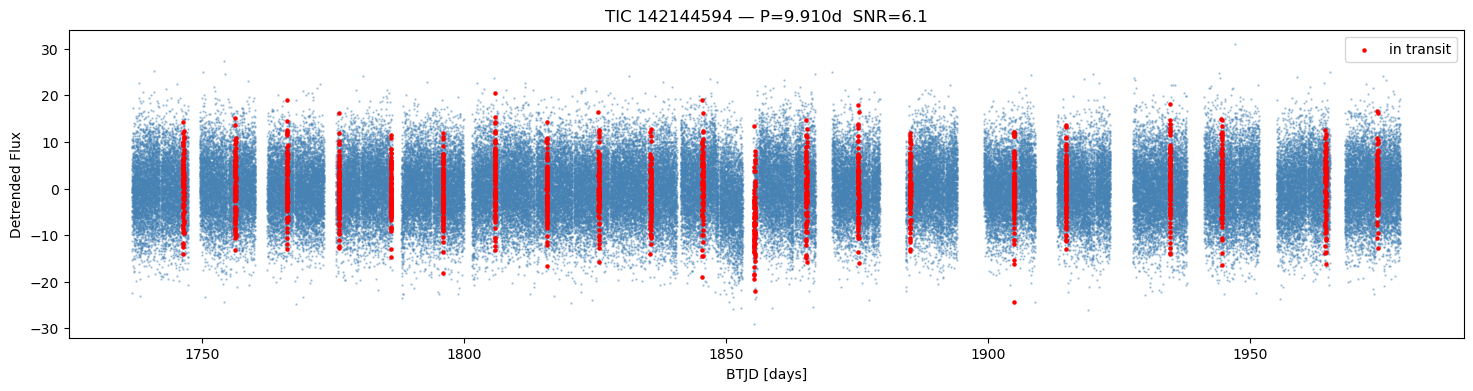

  CM p-value:  0.04904
  EOP p-value: 0.8371
  CM p-value:  0.1135
  EOP p-value: 0.9847
  CM p-value:  0.4943
  EOP p-value: 0.852
  CM p-value:  0.3289
  EOP p-value: 0.6218
  CM p-value:  0.7462
  EOP p-value: 0.2251
  CM p-value:  0.02137
  EOP p-value: 0.702
  CM p-value:  0.08931
  EOP p-value: 0.7818
  CM p-value:  0.3602
  EOP p-value: 0.9914
  CM p-value:  0.04222
  EOP p-value: 0.9783

REAL DATA VETTING RESULT
  Detected period:  9.9097 d
  Detected SNR:     6.11
  CM combined p:    0.003426
  EvenOdd comb. p:  0.9992
  Weighted score:   0.2524

  Result: PASSES vetting — consistent with a real planet signal. ✓


0

In [8]:
# testing vetting on non injected transit 

# getting the data (results from the search hence the results)
RESULTS_DIR = "/home/juliajos/tess_transit/data/output_y5/"
LAB_DIR     = "/home/juliajos/TESS/data/lightcurves_y5/"
TARGET_ID   = "142144594"  # a year 5 target
SECTORS     = [61, 62, 63, 64, 65, 66, 67, 68, 69]

# load in the FFT Serch Results
try:
    with open(results_path, "rb") as f:
        results_real = pickle.load(f)
    print(f"[{TARGET_ID}] Loaded pre-saved search results.")
except Exception as e:
    raise RuntimeError(f"Could not load results pickle: {e}")

# best SNR fit from the search script (hence the [0])
best_real = results_real['best_candidates'][0]                               ### change FFT index here ###

print(f"\nDetected period:  {best_real['period_cadences']} cad ({best_real['period_days']:.3f} days)")
print(f"Detected SNR:     {best_real['snr']:.2f}")

det_period_days   = best_real['period_days'] #det for detected
det_duration_days = cadence_to_days(best_real['duration'])

#loading in real data
lab_path = os.path.join(LAB_DIR, f"{TARGET_ID}.p")

try:
    with open(lab_path, "rb") as f:
        (lc_data, processed_lc_data, detrend_data, norm_offset, quality_data,
         time_data, cam_data, ccd_data, coeff_ls,
         centroid_xy_data, pos_xy_corr) = pickle.load(f)
except Exception as e:
    raise RuntimeError(f"Could not load lab pickle: {e}")

sector61_start_cad = np.asarray(time_data[SECTORS[0]])[0]
det_t0_btjd = epoch_to_btjd(sector61_start_cad + best_real['epoch_cadences'], best_real['duration'])


# plot stitched light curve with transit marked
cad  = np.concatenate([np.asarray(time_data[s]) for s in SECTORS if s in time_data])
flux = np.concatenate([np.asarray(detrend_data[s].unmasked) for s in SECTORS if s in detrend_data])
bjd  = cad * (120 / 86400)

P   = det_period_days
t0  = det_t0_btjd
dur = det_duration_days
phase     = ((bjd - t0 + 0.5*P) % P) - 0.5*P
intransit = np.abs(phase) <= 0.5*dur

plt.figure(figsize=(18, 4))
plt.scatter(bjd, flux, s=0.5, alpha=0.4, color='steelblue')
plt.scatter(bjd[intransit], flux[intransit], s=5, color='red', label='in transit')
plt.xlabel("BTJD [days]")
plt.ylabel("Detrended Flux")
plt.title(f"TIC {TARGET_ID} — P={P:.3f}d  SNR={best_real['snr']:.1f}")
plt.legend()
plt.show()

#running vetting tests sector by sector
sector_cm_pvals  = []
sector_eop_pvals = []

for sector in SECTORS:
    try:
        lc_sector   = np.array(detrend_data[sector].unmasked)
        time_sector = np.asarray(time_data[sector], dtype=float)
        time_btjd_s  = cadences_to_btjd(time_sector) #time in btjd, s for sector not total

        pos_xy_sector = pos_xy_corr[sector]
        mom_xy        = centroid_xy_data[sector]
        pos_cor1 = np.array(pos_xy_sector[0].unmasked)
        pos_cor2 = np.array(pos_xy_sector[1].unmasked)
        mom1     = np.array(mom_xy[0].unmasked)
        mom2     = np.array(mom_xy[1].unmasked)
    except Exception as e:
        print(f"  Data extraction failed: {e}, skipping.")
        continue

    #centroid motion test, per sector
    try:
        cm_p = calculate_enhanced_centroid_motion_pvalue(
            lc_sector, time_btjd=time_btjd_s,
            mom1=mom1, mom2=mom2, pos1=pos_cor1, pos2=pos_cor2,
            period_days=det_period_days, t0_btjd=det_t0_btjd,
            duration_days=max(det_duration_days, cadence_to_days(6)),
            baseline_factor=3.0, sector=sector, plot=plot
        )
    except Exception as e:
        print(f"  CM test failed: {e}")
        cm_p = np.nan
    sector_cm_pvals.append(cm_p)
    print(f"  CM p-value:  {cm_p:.4g}" if not np.isnan(cm_p) else "  CM: NaN")

    #bin for even-odd test
    try:
        bin_size    = 0.005
        bins        = np.arange(np.min(time_btjd_s), np.max(time_btjd_s) + bin_size, bin_size)
        bin_indices = np.digitize(time_btjd_s, bins)
        b_time, b_flux = [], [] #b for binned
        for i in range(1, len(bins)):
            mask = bin_indices == i
            if np.any(mask):
                b_time.append(np.mean(time_btjd_s[mask]))
                b_flux.append(np.mean(lc_sector[mask]))
        b_time = np.array(b_time)
        b_flux = np.array(b_flux)

        eop = even_odd_phase_our_data(
            b_flux, time_btjd=b_time,
            period_days=det_period_days, t0_btjd=det_t0_btjd,
            duration_days=det_duration_days,
            plot_size=0.15, same_axes=False, plot= False
        )
    except Exception as e:
        print(f"  Even-odd test failed: {e}")
        eop = np.nan
    sector_eop_pvals.append(eop)
    print(f"  EOP p-value: {eop:.4g}" if not np.isnan(eop) else "  EOP: NaN")

    del lc_sector, time_sector, time_btjd_s
    del pos_cor1, pos_cor2, mom1, mom2
    del b_time, b_flux
    gc.collect()

#getting combined p values and printing results
combined_cm_p  = stouffers_method(sector_cm_pvals)
combined_eop_p = stouffers_method(sector_eop_pvals)
score = (combined_score_weighted(combined_cm_p, combined_eop_p)
         if not np.isnan(combined_cm_p) and not np.isnan(combined_eop_p)
         else np.nan)

print("\n" + "=" * 60)
print("REAL DATA VETTING RESULT")
print("=" * 60)
print(f"  Detected period:  {det_period_days:.4f} d")
print(f"  Detected SNR:     {best_real['snr']:.2f}")
print(f"  CM combined p:    {combined_cm_p:.4g}")
print(f"  EvenOdd comb. p:  {combined_eop_p:.4g}")
print(f"  Weighted score:   {score:.4g}")
print()

#interpretation (just for conceptual sense, this doesn't go anywhere except printed)
if np.isnan(score):
    print("  Result: could not compute score (insufficient data).")
# CORRECT
elif score < 0.02:
    print("  Result: FAILS vetting — flagged as likely false positive (low score). ✗")
elif score < 0.05:
    print("  Result: WARN — borderline signal, check manually.")
else:
    print("  Result: PASSES vetting — consistent with a real planet signal. ✓")
    
#clean up - otherwise the kernel will die when you run all the targets at once
del lc_data, processed_lc_data, detrend_data, norm_offset, quality_data
del time_data, cam_data, ccd_data, coeff_ls, centroid_xy_data, pos_xy_corr
del results_real
gc.collect()

# Running the vetting over all targets in the year 5 search pipeline 

In [9]:
# Results saved to VETTING_DIR as {TIC_TD}_vetting.p

# thresholds for vetting (standard 0.05 threshold for p value significance)
CM_FAIL_ALPHA = 0.05
EOP_FAIL_ALPHA = 0.05
SCORE_FAIL_ALPHA = 0.05
SCORE_WARN_ALPHA = 0.02

# 15 sigma clipping threshold for CM test only
SIGMA_CLIP = 15.0

#targets 
tids = np.loadtxt('/home/juliajos/TESS/data/light_curves/info/persistant_tids_y5.txt', dtype=int)
print(f"Total targets: {len(tids)}")

passed = 0
failed = 0
skipped_no_result = 0

# running vetting on all targets in tids
for TARGET_ID in tids:
    TARGET_ID = str(TARGET_ID)
    out_path = os.path.join(VETTING_DIR, f"{TARGET_ID}_vetting.p")

    #skipping if already vetted
    if os.path.exists(out_path):
        print(f"TIC {TARGET_ID} already vetted, skipping...")
        continue

    results_path = os.path.join(RESULTS_DIR, f"{TARGET_ID}_results.p")
    if not os.path.exists(results_path):
        print(f"TIC {TARGET_ID} has no results, skipping...")
        skipped_no_result += 1
        continue

    try:
        with open(results_path, "rb") as f:
            results_real = pickle.load(f)
    except Exception as e:
        print(f"[{TARGET_ID}] could not load results: {e}")
        continue

    candidates = results_real.get('best_candidates', [])
    if len(candidates) == 0 or candidates[0].get('snr', 0) < 6:
        # no viable candidate - save a FAIL record and move on
        record = {'tid': TARGET_ID, 'status': 'no_candidate'}
        with open(out_path, "wb") as f:
            pickle.dump(record, f)
        failed += 1
        continue

    best_real = candidates[0]                                       # best results from the FFT search using real data, not simulated
    det_period_days   = best_real['period_days']                    # detected period in days
    det_duration_days = cadence_to_days(best_real['duration'])      # detected duration in days

    lab_path = os.path.join(LAB_DIR, f"{TARGET_ID}.p")
    if not os.path.exists(lab_path):
        print(f"[{TARGET_ID}] lab file not found, skipping...")
        continue

    try:
        with open(lab_path, "rb") as f:
            (lc_data, processed_lc_data, detrend_data, norm_offset, quality_data,
             time_data, cam_data, ccd_data, coeff_ls,
             centroid_xy_data, pos_xy_corr) = pickle.load(f)
    except Exception as e:
        print(f"[{TARGET_ID}] Could not load LC: {e}")
        continue

    # t0: epoch is relative to sector 61 start cadence
    sector61_start_cad = np.asarray(time_data[SECTORS[0]])[0]                                                   # sector 61 start cadence
    det_t0_btjd = epoch_to_btjd(sector61_start_cad + best_real['epoch_cadences'], best_real['duration'])        # detected epoch in BTJD

    # norm_factor for depth calculation
    all_flux_raw = np.concatenate([np.asarray(lc_data[s]) for s in SECTORS if s in lc_data])                    # normalization factor for the Rp/Rstar depth calculation
    norm_factor  = float(np.nanmedian(all_flux_raw))

    sector_cm_pvals  = []
    sector_eop_pvals = []

    for sector in SECTORS:
        try:
            lc_sector   = np.array(detrend_data[sector].unmasked)
            time_sector = np.asarray(time_data[sector], dtype=float)
            time_btjd_s = cadences_to_btjd(time_sector)
            pos_xy_sector = pos_xy_corr[sector]
            mom_xy        = centroid_xy_data[sector]
            pos_cor1 = np.array(pos_xy_sector[0].unmasked)
            pos_cor2 = np.array(pos_xy_sector[1].unmasked)
            mom1     = np.array(mom_xy[0].unmasked)
            mom2     = np.array(mom_xy[1].unmasked)
        except Exception as e:
            continue

    # CM test: apply 15-sigma clip to flux ONLY for this test
        try:
            lc_cm = lc_sector.copy()
            med = np.nanmedian(lc_cm)
            std = np.nanstd(lc_cm)
            lc_cm[np.abs(lc_cm - med) > SIGMA_CLIP * std] = med

            cm_p = calculate_enhanced_centroid_motion_pvalue(
                lc_cm, time_btjd=time_btjd_s,
                mom1=mom1, mom2=mom2, pos1=pos_cor1, pos2=pos_cor2,
                period_days=det_period_days, t0_btjd=det_t0_btjd,
                duration_days=max(det_duration_days, cadence_to_days(6)),
                baseline_factor=3.0, sector=sector, plot=False
            )
        except Exception as e:
            cm_p = np.nan
        sector_cm_pvals.append(cm_p)

    # EOP test: NO clipping (so deep EB eclipses are not erased)
        try:
            bin_size    = 0.005
            bins        = np.arange(np.min(time_btjd_s), np.max(time_btjd_s) + bin_size, bin_size)
            bin_indices = np.digitize(time_btjd_s, bins)
            b_time, b_flux_eop = [], []
            for i in range(1, len(bins)):
                mask = bin_indices == i
                if np.any(mask):
                    b_time.append(np.mean(time_btjd_s[mask]))
                    b_flux_eop.append(np.mean(lc_sector[mask]))
            b_time     = np.array(b_time)
            b_flux_eop = np.array(b_flux_eop)

            eop = even_odd_phase_our_data(
                b_flux_eop, time_btjd=b_time,
                period_days=det_period_days, t0_btjd=det_t0_btjd,
                duration_days=det_duration_days,
                plot_size=0.15, same_axes=False, plot=False
            )
        except Exception as e:
            eop = np.nan
        sector_eop_pvals.append(eop)

        del lc_sector, time_sector, time_btjd_s
        del pos_cor1, pos_cor2, mom1, mom2, b_time, b_flux_eop
        gc.collect()

    combined_cm_p  = stouffers_method(sector_cm_pvals)
    combined_eop_p = stouffers_method(sector_eop_pvals)
    score = (combined_score_weighted(combined_cm_p, combined_eop_p)
             if not (np.isnan(combined_cm_p) or np.isnan(combined_eop_p))
             else np.nan)

    # depth calculation
    try:
        bjd_all  = np.concatenate([cadences_to_btjd(np.asarray(time_data[s], dtype=float))
                                   for s in SECTORS if s in time_data])
        flux_all = np.concatenate([np.asarray(detrend_data[s].unmasked)
                                   for s in SECTORS if s in detrend_data])
        sort_idx = np.argsort(bjd_all)
        bjd_all  = bjd_all[sort_idx]
        flux_all = flux_all[sort_idx]

        phase_norm = (((bjd_all - det_t0_btjd + 0.5 * det_period_days)
                       % det_period_days) - 0.5 * det_period_days) / det_period_days
        half_dur   = (det_duration_days / det_period_days) / 2

        bin_size = 0.003
        bins = np.arange(-0.5, 0.5 + bin_size, bin_size)
        b_phase_d, b_flux_d = [], []
        for i in range(1, len(bins)):
            m = (phase_norm >= bins[i-1]) & (phase_norm < bins[i])
            if np.any(m):
                b_phase_d.append(0.5 * (bins[i-1] + bins[i]))
                b_flux_d.append(np.nanmedian(flux_all[m]))
        b_phase_d = np.array(b_phase_d)
        b_flux_d  = np.array(b_flux_d)

        near_transit = np.abs(b_phase_d) < 1 * half_dur
        baseline     = np.nanmedian(b_flux_d[~near_transit]) if np.any(~near_transit) else np.nan
        transit_min  = np.nanmin(b_flux_d[near_transit])     if np.any(near_transit)  else np.nan
        depth_fraction = (baseline - transit_min) / norm_factor if norm_factor != 0 else np.nan
        rp_rs = float(np.sqrt(np.abs(depth_fraction))) if not np.isnan(depth_fraction) else np.nan
    except Exception as e:
        depth_fraction = np.nan
        rp_rs = np.nan

    # determine pass/fail/warn
    if np.isnan(score):
        verdict = 'INSUFFICIENT_DATA'
    elif combined_cm_p < CM_FAIL_ALPHA:
        verdict = 'FAIL_CM'
    elif combined_eop_p < EOP_FAIL_ALPHA:
        verdict = 'FAIL_EOP'
    elif score < SCORE_WARN_ALPHA:
        verdict = 'FAIL_SCORE'
    elif score < SCORE_FAIL_ALPHA:
        verdict = 'WARN'
    else:
        verdict = 'PASS'

    record = {
        'tid':            TARGET_ID,
        'period_days':    det_period_days,
        'duration_days':  det_duration_days,
        't0_btjd':        det_t0_btjd,
        'snr':            best_real['snr'],
        'cm_p':           combined_cm_p,
        'eop_p':          combined_eop_p,
        'score':          score,
        'depth_fraction': depth_fraction,
        'rp_rs':          rp_rs,
        'verdict':        verdict,
    }
    with open(out_path, "wb") as f:
        pickle.dump(record, f)

    if verdict in ('PASS', 'WARN'):
        passed += 1
        print(f"[{TARGET_ID}] {verdict}  P={det_period_days:.3f}d  SNR={best_real['snr']:.1f}  score={score:.3f}  Rp/Rs={rp_rs:.3f}")
    else:
        failed += 1

    del lc_data, processed_lc_data, detrend_data, norm_offset, quality_data
    del time_data, cam_data, ccd_data, coeff_ls, centroid_xy_data, pos_xy_corr
    del results_real, all_flux_raw
    gc.collect()


print(f"\nDone. Passed/Warn: {passed}  Failed: {failed}  No result file: {skipped_no_result}")   


Total targets: 1299
TIC 25077712 already vetted, skipping...
TIC 25077838 already vetted, skipping...
TIC 25078523 already vetted, skipping...
TIC 25116870 already vetted, skipping...
TIC 25131889 already vetted, skipping...
TIC 25131892 already vetted, skipping...
TIC 25132999 already vetted, skipping...
TIC 25134376 already vetted, skipping...
TIC 25153167 already vetted, skipping...
TIC 25153797 already vetted, skipping...
TIC 25155698 already vetted, skipping...
TIC 25155984 already vetted, skipping...
TIC 29759268 already vetted, skipping...
TIC 29777922 already vetted, skipping...
TIC 29778225 already vetted, skipping...
TIC 29780677 already vetted, skipping...
TIC 29781292 already vetted, skipping...
TIC 29830068 already vetted, skipping...
TIC 29830830 already vetted, skipping...
TIC 29831208 already vetted, skipping...
TIC 29832209 already vetted, skipping...
TIC 29925818 already vetted, skipping...
TIC 29986479 already vetted, skipping...
TIC 29986496 already vetted, skipping

### Making 3 figure plots for the targets which have passed vetting 
- Look at the Rp/Rstar depth and phase fold to determine good targets